In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import tensorflow as tf
from tensorflow import keras

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
tf.get_logger().setLevel('ERROR')

print(f'NumPy      version: {np.__version__}')
print(f'pandas     version: {pd.__version__}')
print(f'TensorFlow version: {tf.__version__}')
print('Imports successful.')

NumPy      version: 2.1.3
pandas     version: 2.2.3
TensorFlow version: 2.21.0
Imports successful.


In [2]:
def extract_anomaly_windows(anomaly_labels):
    """Converts binary label array to list of (start, end) tuples."""
    windows   = []
    in_window = False
    start     = 0
    for i, label in enumerate(anomaly_labels):
        if label == 1 and not in_window:
            start     = i
            in_window = True
        elif label == 0 and in_window:
            windows.append((start, i))
            in_window = False
    if in_window:
        windows.append((start, len(anomaly_labels)))
    return windows


def inject_noise_profile(raw_data, start_idx, end_idx, variance=2.5, mode='noise'):
    """Injects noise or blackout into a localized index window."""
    poisoned_data = raw_data.copy()
    window_rows   = end_idx - start_idx
    n_features    = poisoned_data.shape[1]
    if mode == 'noise':
        injection = np.random.normal(0, variance, size=(window_rows, n_features))
        poisoned_data[start_idx:end_idx, :] += injection
    elif mode == 'blackout':
        poisoned_data[start_idx:end_idx, :] = 0.0
    else:
        raise ValueError(f"Unknown mode: '{mode}'.")
    return poisoned_data


print('Carry-forward functions loaded.')

Carry-forward functions loaded.


In [3]:
def make_synthetic_skab_file(filepath, n_rows, anomaly_windows, seed=0):
    np.random.seed(seed)
    t       = np.linspace(0, 50, n_rows)
    sensors = {}
    names   = ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current',
                'Pressure', 'Temperature', 'Thermocouple',
                'Voltage', 'Volume Flow RateRMS']
    for i, name in enumerate(names):
        sensors[name] = np.sin(t * (i + 1)) + np.random.normal(0, 0.05, n_rows)
    labels      = np.zeros(n_rows, dtype=int)
    changepoint = np.zeros(n_rows, dtype=int)
    for s, e in anomaly_windows:
        labels[s:e]    = 1
        changepoint[s] = 1
    idx = pd.date_range('2020-01-01', periods=n_rows, freq='1s')
    df  = pd.DataFrame(sensors, index=idx)
    df.index.name = 'datetime'
    df['anomaly']     = labels
    df['changepoint'] = changepoint
    df.to_csv(filepath, sep=';')


synth_dir = Path('synthetic_alldata')
synth_dir.mkdir(exist_ok=True)

files_spec = [
    ('1.csv', 800,  [(150, 230), (500, 580)]),
    ('2.csv', 1000, [(200, 350)]),
    ('3.csv', 600,  []),
    ('4.csv', 900,  [(100, 160), (400, 480), (700, 750)]),
    ('5.csv', 750,  [(300, 420)]),
]

for fname, n_rows, windows in files_spec:
    make_synthetic_skab_file(synth_dir / fname, n_rows, windows)

print('Synthetic SKAB dataset ready.')
for fname, n_rows, windows in files_spec:
    print(f'  {fname}: {n_rows} rows, {len(windows)} anomaly window(s)')

Synthetic SKAB dataset ready.
  1.csv: 800 rows, 2 anomaly window(s)
  2.csv: 1000 rows, 1 anomaly window(s)
  3.csv: 600 rows, 0 anomaly window(s)
  4.csv: 900 rows, 3 anomaly window(s)
  5.csv: 750 rows, 1 anomaly window(s)


In [4]:
def make_windows(X, window_size=32, step=4):
    """
    Extracts overlapping sliding windows from a (T, F) sensor array.

    Parameters
    ----------
    X           : np.ndarray, shape (T, F)
    window_size : int — timesteps per window
    step        : int — stride between consecutive windows

    Returns
    -------
    windows : np.ndarray, shape (N, window_size, F)
    indices : np.ndarray of int — start index of each window in X
    """
    # TODO: compute T = X.shape[0]
    T = X.shape[0]
    # TODO: compute start indices using np.arange(0, T - window_size + 1, step)
    starts = np.arange(0, T - window_size + 1, step)
    # TODO: stack slices X[s : s + window_size] using np.stack
    windows = np.stack(
    [X[s:s+window_size] for s in starts]
)
    # TODO: return (windows, starts)
    return windows, starts

    #pass


# Shape check — must pass before continuing
dummy = np.random.randn(600, 8)
W, idx = make_windows(dummy, window_size=32, step=4)
expected_N = (600 - 32) // 4 + 1   # = 143
assert W.shape == (expected_N, 32, 8), f'Expected ({expected_N}, 32, 8), got {W.shape}'
assert len(idx) == expected_N
print(f'make_windows shape check passed: {W.shape}')

make_windows shape check passed: (143, 32, 8)


In [8]:
def build_autoencoder(window_size=32, n_features=8):
    """
    Builds and compiles a 1D convolutional autoencoder.

    Architecture
    ------------
    Input  (window_size, n_features)
    Encoder: Conv1D(16,3,relu,same) → MaxPool(2) → Conv1D(8,3,relu,same) → MaxPool(2)
    Decoder: Conv1D(8,3,relu,same) → UpSample(2) → Conv1D(16,3,relu,same) → UpSample(2)
             → Conv1D(n_features,3,linear,same)
    Output (window_size, n_features)

    Returns
    -------
    model : compiled keras.Model
    """
    inp = keras.Input(shape=(window_size, n_features))

    # TODO: Encoder — Conv1D(16,3,relu,same) → MaxPool(2) → Conv1D(8,3,relu,same) → MaxPool(2)

    x = keras.layers.Conv1D(
    16,
    3,
    activation='relu',
    padding='same'
    )(inp)

    x = keras.layers.MaxPooling1D(2)(x)

    x = keras.layers.Conv1D(
        8,
        3,
        activation='relu',
        padding='same'
        )(x)

    x = keras.layers.MaxPooling1D(2)(x)


    # TODO: Decoder — Conv1D(8,3,relu,same) → UpSample(2) → Conv1D(16,3,relu,same) → UpSample(2)
    #                → Conv1D(n_features,3,linear,same) → assign to `out`

  # Decoder

    x = keras.layers.Conv1D(
        8,
        3,
        activation='relu',
        padding='same'
        )(x)

    x = keras.layers.UpSampling1D(2)(x)

    x = keras.layers.Conv1D(
        16,
        3,
        activation='relu',
        padding='same'
        )(x)

    x = keras.layers.UpSampling1D(2)(x)

    out = keras.layers.Conv1D(
        n_features,
        3,
        activation='linear',
        padding='same'
        )(x)



    model = keras.Model(inp, out)
    model.compile(optimizer='adam', loss='mse')
    return model


# Shape check: output must match input
model = build_autoencoder(window_size=32, n_features=8)
test_in  = np.random.randn(4, 32, 8).astype(np.float32)
test_out = model.predict(test_in, verbose=0)
assert test_out.shape == test_in.shape, f'Shape mismatch: {test_out.shape}'
print(f'build_autoencoder shape check passed: {test_out.shape}')
model.summary()

build_autoencoder shape check passed: (4, 32, 8)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 32, 16)         │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 16, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 16, 8)          │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 8, 8)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 8, 8)           │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d (UpSampling1D)    │ (None, 16, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 16, 16)         │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_1 (UpSampling1D)  │ (None, 32, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 32, 8)          │           392 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,784 (6.97 KB)

 Trainable params: 1,784 (6.97 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
DATA_DIR = Path('synthetic_alldata')   # swap to Path('SKAB/alldata') for real data

SENSOR_COLS = ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current',
               'Pressure', 'Temperature', 'Thermocouple',
               'Voltage', 'Volume Flow RateRMS']
WINDOW_SIZE = 32
STEP        = 4

# Load 3.csv (clean file) as training data
df_clean = pd.read_csv(DATA_DIR / '3.csv', sep=';', index_col='datetime', parse_dates=True)
X_clean  = df_clean[SENSOR_COLS].values.astype(np.float32)

X_train, _ = make_windows(X_clean, WINDOW_SIZE, STEP)
print(f'Training windows: {X_train.shape}  (N, W, F)')

tf.random.set_seed(42)
np.random.seed(42)

model = build_autoencoder(window_size=WINDOW_SIZE, n_features=X_train.shape[2])

history = model.fit(
    X_train, X_train,
    epochs=15,
    batch_size=16,
    validation_split=0.1,
    verbose=1
)

train_loss = history.history['loss']
print(f'\nInitial loss : {train_loss[0]:.6f}')
print(f'Final   loss : {train_loss[-1]:.6f}')
assert train_loss[-1] < train_loss[0], 'Training loss did not decrease!'
print('Training loss decreased — model is learning.')

model.save('autoencoder_week05.keras')
print('Model saved to autoencoder_week05.keras')

Training windows: (143, 32, 8)  (N, W, F)
Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.5144 - val_loss: 0.4941
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4844 - val_loss: 0.4802
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4688 - val_loss: 0.4639
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.4502 - val_loss: 0.4431
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4277 - val_loss: 0.4206
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.4030 - val_loss: 0.3959
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.3764 - val_loss: 0.3686
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.3457 - val_loss: 0.3385
Epoch 9/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.3134 - val_loss: 0.3105
Epoch 10/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2871 - val_loss: 0.2898
Epoch 11/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2656 - val_loss: 0.2704
Epoch 12/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12m

In [10]:
def reconstruction_error(model, X, window_size=32, step=4):
    """
    Computes per-window MSE reconstruction error for a sensor array.

    Parameters
    ----------
    model       : trained keras.Model
    X           : np.ndarray, shape (T, F)
    window_size : int
    step        : int

    Returns
    -------
    errors  : np.ndarray, shape (N,) — MSE per window
    indices : np.ndarray of int — start index of each window
    """
    # TODO: call make_windows(X, window_size, step) → windows, indices
    windows, indices = make_windows(
    X,
    window_size,
    step
)
    # TODO: call model.predict(windows.astype(np.float32), verbose=0) → reconstructed
    reconstructed = model.predict(
    windows.astype(np.float32),
    verbose=0
)
    # TODO: compute per-window MSE: np.mean((windows - reconstructed) ** 2, axis=(1, 2))
    errors = np.mean(
    (windows - reconstructed) ** 2,
    axis=(1, 2)
)
    # TODO: return (errors, indices)
    return errors, indices
   # pass


# Load 4.csv — 3 anomaly windows
df4 = pd.read_csv(DATA_DIR / '4.csv', sep=';', index_col='datetime', parse_dates=True)
X4_clean  = df4[SENSOR_COLS].values.astype(np.float32)
labels4   = df4['anomaly'].values.astype(int)
windows4  = extract_anomaly_windows(labels4)
print(f'4.csv anomaly windows: {windows4}')

# Contaminate 4.csv with noise
np.random.seed(42)
X4_cont = X4_clean.copy()
for s, e in windows4:
    X4_cont = inject_noise_profile(X4_cont, s, e, variance=2.5, mode='noise')

# Compute reconstruction errors
err_clean, idx_clean = reconstruction_error(model, X4_clean, WINDOW_SIZE, STEP)
err_cont,  idx_cont  = reconstruction_error(model, X4_cont,  WINDOW_SIZE, STEP)

print(f'\nClean        — mean error: {err_clean.mean():.6f}')
print(f'Contaminated — mean error: {err_cont.mean():.6f}')

# Key assertion: contaminated error must be higher
assert err_cont.mean() > err_clean.mean(), \
    f'Expected contaminated error ({err_cont.mean():.6f}) > clean ({err_clean.mean():.6f})'
print('Assertion passed: contaminated mean error > clean mean error.')


4.csv anomaly windows: [(100, 160), (400, 480), (700, 750)]

Clean        — mean error: 0.231099
Contaminated — mean error: 1.820564
Assertion passed: contaminated mean error > clean mean error.


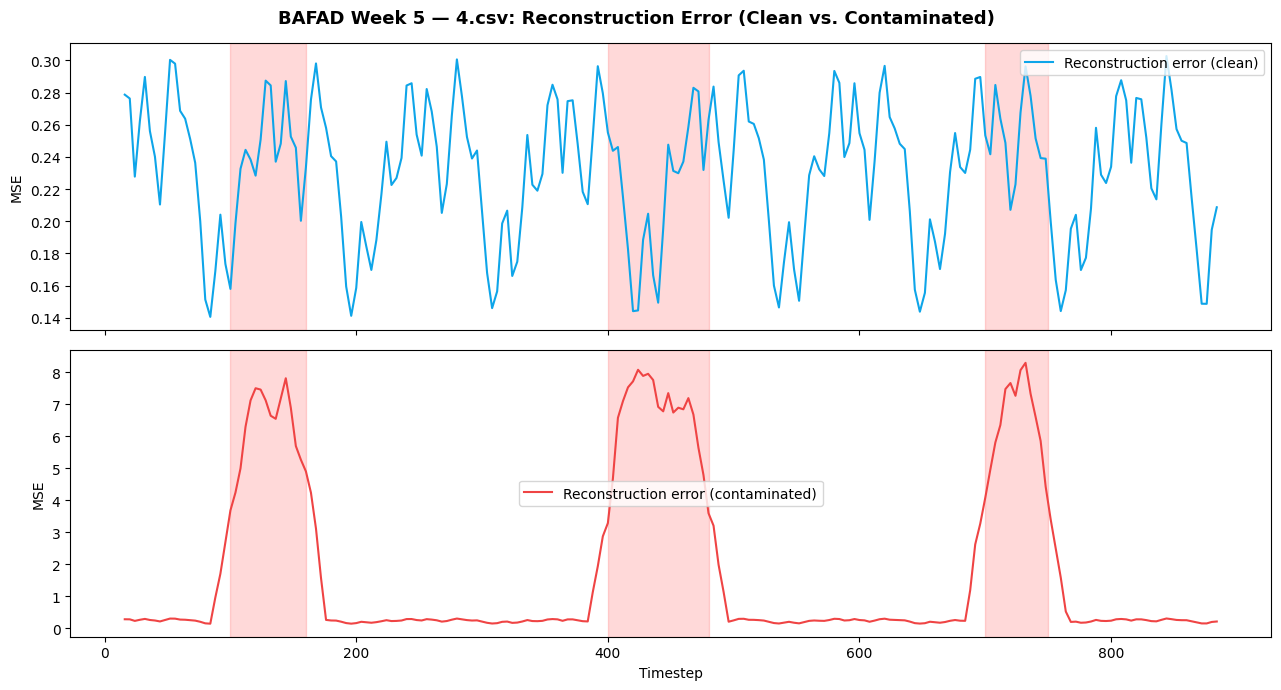

Plot saved to week05_exercise1_plot.png


In [11]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

# Map each window to its center timestep
center_clean = idx_clean + WINDOW_SIZE // 2
center_cont  = idx_cont  + WINDOW_SIZE // 2

# TODO: Plot err_clean on axes[0] (color='#0EA5E9', label='Reconstruction error (clean)')
axes[0].plot(
    center_clean,
    err_clean,
    color='#0EA5E9',
    label='Reconstruction error (clean)'
)
# TODO: Plot err_cont  on axes[1] (color='#EF4444', label='Reconstruction error (contaminated)')
axes[1].plot(
    center_cont,
    err_cont,
    color='#EF4444',
    label='Reconstruction error (contaminated)'
)
# TODO: Add anomaly window shading to both panels (axvspan, alpha=0.15, color='red')
for s, e in windows4:

    axes[0].axvspan(
        s,
        e,
        alpha=0.15,
        color='red'
    )

    axes[1].axvspan(
        s,
        e,
        alpha=0.15,
        color='red'
    )
# TODO: Add ylabel='MSE' and legend to each panel; add xlabel to axes[1]
axes[0].set_ylabel('MSE')
axes[0].legend()
axes[1].set_ylabel('MSE')
axes[1].set_xlabel('Timestep')
axes[1].legend()

fig.suptitle('BAFAD Week 5 — 4.csv: Reconstruction Error (Clean vs. Contaminated)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('week05_exercise1_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved to week05_exercise1_plot.png')

Q1. Why is the autoencoder trained only on clean data? What would happen to anomaly detection performance if contaminated windows were included in training?

The autoencoder is only trained on normal data so it knows what normal behavior looks like. That way when an anomily does happen, it has a higher reconstruction error because of how unfamiliar it is.

Q2. make_windows() uses step=4 and window_size=32. How many windows are extracted from a 600-row file? Show your calculation.

The number of windows is calculated by N - (T - window_size) // step + 1. This gives us N = (600 - 32) // 4 + 1 which gives us N = 143.

Q3. A student plots reconstruction error and sees high error throughout the entire file, not just in the anomaly windows. Name two possible causes and one diagnostic step for each.

One possibility is that the model was not trained well enough such as not haing enough training. Anouther reason could be that the data really is that different from the normal data.

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
